# HW1 : Introduction and Learnability

**BENZOHRA Elhachemi M2 IMDS**

Dans ce devoir je compare le cadre PAC et le cadre Agnostic PAC sur un problème simple : apprendre un seuil sur l'intervalle [0, 1] avec l'algorithme ERM.

Le problème :
- les points $x$ sont tirés uniformément dans $[0, 1]$ ;
- la vraie fonction est $f_\theta(x) = 1$ si $x > \theta$ et $0$ sinon ;
- dans le cas réalisable, $y = f_\theta(x)$ ;
- dans le cas agnostique, chaque label est inversé avec une probabilité $\eta$.

Paramètres :
- $\theta = 0.4$ ;
- $\varepsilon = 0.1$ et $\delta = 0.05$, c'est-à-dire qu'on veut une erreur d'au plus 10 % avec une confiance de 95 % ;
- $\eta = 0.2$ pour le bruit : assez grand pour bien voir l'effet, et plus petit que 0.5 pour que $f_\theta$ reste le meilleur seuil ;
- 1000 répétitions par taille, et un test set de 100 000 points pour estimer l'erreur vraie.

`numpy` pour les calculs et `matplotlib` pour les graphiques. L'algorithme ERM est codé à la main.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)

theta = 0.4        # seuil de la vraie fonction
eps = 0.1          # erreur tolérée
delta = 0.05       # probabilité d'échec tolérée
eta = 0.2          # taux de bruit
tailles = [5, 10, 20, 50, 100, 200]
n_rep = 1000       # nombre de répétitions
n_test = 100000    # taille du test set

## 1. Data Generation

La fonction `generer` tire m points au hasard et calcule leurs labels. Le paramètre `bruit` sert pour la partie 5 : s'il vaut 0, on est dans le cas réalisable.

In [3]:
def f(x):
    return (x > theta).astype(int)

def generer(m, bruit=0.0):
    x = rng.uniform(0, 1, m)
    y = f(x)
    if bruit > 0:
        inverse = rng.uniform(0, 1, m) < bruit
        y[inverse] = 1 - y[inverse]
    return x, y

# un training set pour chaque taille
donnees = {}
for m in tailles:
    donnees[m] = generer(m)
    x, y = donnees[m]
    print("m =", m, ": ", y.sum(), "labels 1 et", m - y.sum(), "labels 0")

m = 5 :  3 labels 1 et 2 labels 0
m = 10 :  6 labels 1 et 4 labels 0
m = 20 :  13 labels 1 et 7 labels 0
m = 50 :  29 labels 1 et 21 labels 0
m = 100 :  67 labels 1 et 33 labels 0
m = 200 :  108 labels 1 et 92 labels 0


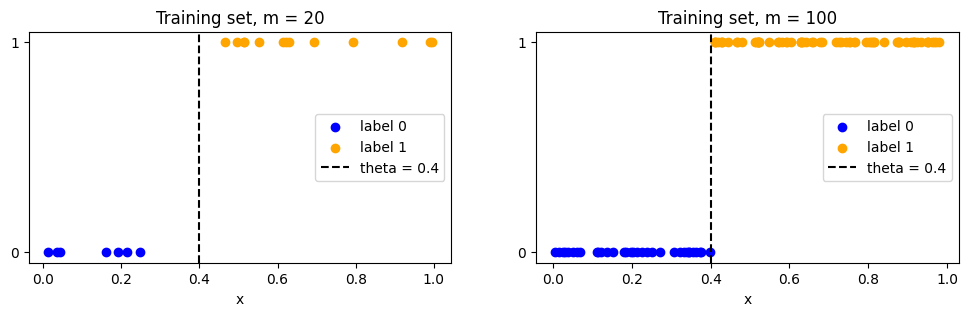

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, m in zip(axes, [20, 100]):
    x, y = donnees[m]
    ax.scatter(x[y == 0], y[y == 0], color="blue", label="label 0")
    ax.scatter(x[y == 1], y[y == 1], color="orange", label="label 1")
    ax.axvline(theta, color="black", linestyle="--", label="theta = 0.4")
    ax.set_title("Training set, m = " + str(m))
    ax.set_xlabel("x")
    ax.set_yticks([0, 1])
    ax.legend(loc="center right")
plt.show()

**Commentaire.** Tous les points à gauche de $\theta$ ont le label 0 et tous ceux à droite ont le label 1, donc un seuil peut séparer parfaitement les données.

Entre le dernier point bleu et le premier point orange il y a un espace vide. Le learner ne peut pas savoir où se trouve $\theta$ dans cet espace. Avec m = 100 cet espace est beaucoup plus petit qu'avec m = 20, donc on s'attend à ce que le seuil soit mieux estimé quand m augmente.

## 2. Implementation of ERM

ERM choisit le seuil qui fait le moins d'erreurs sur le training set :

$$h_S = \arg\min_{h \in \mathcal{H}} L_S(h), \qquad L_S(h) = \frac{\text{nombre d'exemples mal classés}}{m}$$

**Stratégie :** Il y a une infinité de seuils possibles, mais on n'a pas besoin de tous les essayer. Si deux seuils sont entre les deux mêmes points voisins du training set, ils classent tous les points de la même façon, donc ils ont la même erreur empirique. Il suffit donc de tester un seul seuil par intervalle.

Les étapes :
1. je trie les points et j'ajoute les bords 0 et 1
2. je prends le milieu de chaque intervalle entre deux points voisins, ce qui donne m + 1 seuils candidats
3. je calcule l'erreur empirique de chaque candidat
4. je garde celui qui a la plus petite erreur (le premier s'il y a égalité).

J'ai choisi le milieu de l'intervalle parce qu'il n'y a pas de raison de préférer un côté plutôt que l'autre.

In [5]:
def predire(t, x):
    return (x > t).astype(int)

def erreur(t, x, y):
    return np.mean(predire(t, x) != y)

def erm(x, y):
    # test : un seuil dans chaque intervalle entre deux points consécutifs
    points = np.concatenate(([0], np.sort(x), [1]))
    candidats = (points[:-1] + points[1:]) / 2      # milieux des intervalles
    erreurs = [erreur(t, x, y) for t in candidats]
    i = np.argmin(erreurs)                          # le premier minimum
    return candidats[i], erreurs[i]

# test : training set de taille 20
x, y = donnees[20]
t, e = erm(x, y)
print("seuil trouvé :", round(t, 4), " erreur empirique :", e)

seuil trouvé : 0.3569  erreur empirique : 0.0


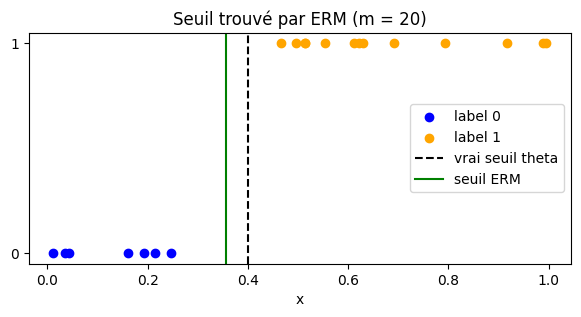

In [7]:
x, y = donnees[20]
t, e = erm(x, y)
plt.figure(figsize=(7, 3))
plt.scatter(x[y == 0], y[y == 0], color="blue", label="label 0")
plt.scatter(x[y == 1], y[y == 1], color="orange", label="label 1")
plt.axvline(theta, color="black", linestyle="--", label="vrai seuil theta")
plt.axvline(t, color="green", label="seuil ERM")
plt.title("Seuil trouvé par ERM (m = 20)")
plt.xlabel("x")
plt.yticks([0, 1])
plt.legend(loc="center right")
plt.show()

**Commentaire.** Le seuil trouvé par ERM (en vert) tombe dans l'espace vide entre les deux classes, donc il classe correctement tous les points du training set. Il est proche du vrai seuil mais pas égal : ici ERM trouve 0.357 alors que $\theta = 0.4$.

## 3. Performance Evaluation

Pour chaque training set je calcule deux erreurs :
- l'**erreur empirique** $L_S(h)$, sur le training set ;
- l'**erreur vraie** $L_D(h)$, la probabilité de se tromper sur un nouvel exemple. On ne peut pas la calculer exactement, donc je l'estime sur un grand test set de 100 000 points généré à part.

In [8]:
x_test, y_test = generer(n_test)

print("  m   seuil ERM   erreur empirique   erreur vraie (test)")
for m in tailles:
    x, y = donnees[m]
    t, e_emp = erm(x, y)
    e_vraie = erreur(t, x_test, y_test)
    print(f"{m:4d}   {t:8.4f}   {e_emp:14.4f}   {e_vraie:14.4f}")

  m   seuil ERM   erreur empirique   erreur vraie (test)
   5     0.4626           0.0000           0.0616
  10     0.3741           0.0000           0.0265
  20     0.3569           0.0000           0.0437
  50     0.3951           0.0000           0.0052
 100     0.4046           0.0000           0.0048
 200     0.4077           0.0000           0.0080


**Commentaire.**

- L'erreur empirique vaut 0 pour toutes les tailles. C'est normal : dans le cas réalisable, il existe un seuil parfait dans $\mathcal{H}$, donc ERM trouve toujours un seuil sans erreur sur le training set.
- L'erreur vraie, elle, n'est pas nulle. Avoir 0 erreur sur le training set ne veut donc pas dire que le modèle est parfait sur de nouvelles données.
- L'erreur vraie est globalement plus petite pour les grands $m$ (0.06 pour $m = 5$, moins de 0.01 à partir de $m = 50$), mais elle ne diminue pas à chaque étape : elle est plus grande pour $m = 20$ (0.044) que pour $m = 10$ (0.027). Ici j'ai un seul training set par taille, donc le résultat dépend de la chance du tirage. C'est pour ça qu'il faut répéter l'expérience, ce que je fais dans la partie suivante.

## 4. Experimental Verification of PAC Learning

D'après le cours, $\mathcal{H}$ est PAC learnable si, avec assez d'exemples, on a

$$\Pr\big(L_D(h_S) \le \varepsilon\big) \ge 1 - \delta$$

ce qui revient à dire $\Pr(L_D(h_S) > \varepsilon) \le \delta$.

Pour estimer cette probabilité, pour chaque taille $m$ je génère 1000 training sets différents, je lance ERM sur chacun et je compte la proportion de fois où l'erreur vraie dépasse $\varepsilon = 0.1$.

In [9]:
def experience(bruit):
    # pour chaque taille : n_rep training sets, on garde les deux erreurs à chaque fois
    x_test, y_test = generer(n_test, bruit)
    resultats = {}
    for m in tailles:
        emp = np.zeros(n_rep)
        vraie = np.zeros(n_rep)
        for r in range(n_rep):
            x, y = generer(m, bruit)
            t, emp[r] = erm(x, y)
            vraie[r] = erreur(t, x_test, y_test)
        resultats[m] = (emp, vraie)
    meilleure = erreur(theta, x_test, y_test)   # erreur du vrai seuil sur le test set
    return resultats, meilleure

res, _ = experience(0)

print("  m   erreur emp. moyenne   erreur vraie moyenne   P(L > eps)")
proba = []
for m in tailles:
    emp, vraie = res[m]
    p = np.mean(vraie > eps)
    proba.append(p)
    print(f"{m:4d}   {emp.mean():14.4f}   {vraie.mean():18.4f}   {p:12.3f}")

  m   erreur emp. moyenne   erreur vraie moyenne   P(L > eps)
   5           0.0000               0.0786          0.320
  10           0.0000               0.0431          0.092
  20           0.0000               0.0237          0.010
  50           0.0000               0.0092          0.000
 100           0.0000               0.0046          0.000
 200           0.0000               0.0025          0.000


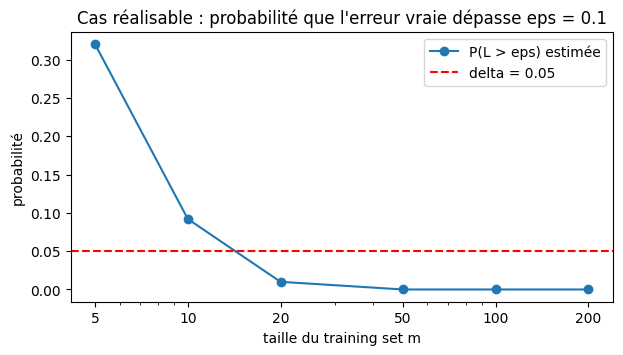

In [10]:
plt.figure(figsize=(7, 3.5))
plt.plot(tailles, proba, "o-", label="P(L > eps) estimée")
plt.axhline(delta, color="red", linestyle="--", label="delta = 0.05")
plt.xscale("log")
plt.xticks(tailles, tailles)
plt.xlabel("taille du training set m")
plt.ylabel("probabilité")
plt.title("Cas réalisable : probabilité que l'erreur vraie dépasse eps = 0.1")
plt.legend()
plt.show()

**Commentaire.**

- La probabilité que l'erreur vraie dépasse $\varepsilon$ diminue très vite quand m augmente : 0.32 pour m = 5, 0.09 pour m = 10, 0.01 pour m = 20, et plus aucun cas sur 1000 à partir de m = 50.
- Elle passe sous $\delta = 0.05$ dès m = 20. Donc avec 20 exemples, ERM obtient une erreur d'au plus 10 % dans plus de 95 % des cas : c'est exactement la garantie PAC.
- L'erreur vraie moyenne tend vers 0, et elle est à peu près divisée par 2 chaque fois que m double (0.079, 0.043, 0.024, ...).
- L'erreur empirique est toujours 0, dans les 6000 expériences.

On retrouve bien le sens de PAC : avec assez de données, le résultat est probablement (probabilité au moins $1 - \delta$) approximativement (erreur au plus $\varepsilon$) correct.

## 5. From PAC to Agnostic PAC

Maintenant chaque label est inversé avec une probabilité $\eta = 0.2$ ,les mêmes expériences qu'avant, avec le même algorithme ERM. Le test set est aussi bruité, car il doit venir de la même distribution que le training set.

Avec le bruit, même le vrai seuil $\theta$ se trompe sur les exemples dont le label a été inversé, donc environ 20 % du temps. Aucun seuil ne peut faire mieux, donc la meilleure erreur possible dans $\mathcal{H}$ est $\eta = 0.2$ et plus 0. L'hypothèse de realizability n'est plus vraie.

labels inversés : 20 sur 100
seuil ERM : 0.3736  erreur empirique : 0.19


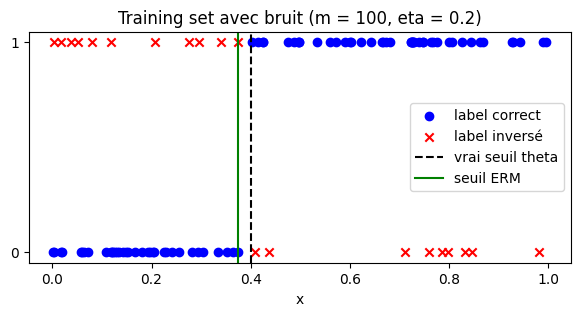

In [11]:
x, y = generer(100, eta)
faux = y != f(x)      # labels qui ont été inversés
t, e = erm(x, y)
print("labels inversés :", faux.sum(), "sur 100")
print("seuil ERM :", round(t, 4), " erreur empirique :", e)

plt.figure(figsize=(7, 3))
plt.scatter(x[~faux], y[~faux], color="blue", label="label correct")
plt.scatter(x[faux], y[faux], color="red", marker="x", label="label inversé")
plt.axvline(theta, color="black", linestyle="--", label="vrai seuil theta")
plt.axvline(t, color="green", label="seuil ERM")
plt.title("Training set avec bruit (m = 100, eta = 0.2)")
plt.xlabel("x")
plt.yticks([0, 1])
plt.legend(loc="center right")
plt.show()

**Commentaire.** Les croix rouges sont les labels inversés : il y a des labels 1 à gauche de $\theta$ et des labels 0 à droite. Aucun seuil ne peut plus séparer parfaitement les données. Le seuil ERM reste proche de $\theta$, mais son erreur empirique est de 0.19 au lieu de 0.

In [12]:
x_test_b, y_test_b = generer(n_test, eta)    # test set bruité

print("  m   seuil ERM   erreur empirique   erreur vraie (test)")
for m in tailles:
    x, y = generer(m, eta)                   # un training set bruité par taille
    t, e_emp = erm(x, y)
    e_vraie = erreur(t, x_test_b, y_test_b)
    print(f"{m:4d}   {t:8.4f}   {e_emp:14.4f}   {e_vraie:14.4f}")

  m   seuil ERM   erreur empirique   erreur vraie (test)
   5     0.4242           0.0000           0.2171
  10     0.2472           0.1000           0.2955
  20     0.3217           0.1500           0.2507
  50     0.4297           0.1200           0.2202
 100     0.3985           0.2000           0.2031
 200     0.4041           0.1900           0.2046


**Commentaire.** Ce tableau refait la partie 3 avec du bruit, avec un training set par taille.

- L'erreur empirique n'est plus nulle, sauf pour $m = 5$ où par chance les 5 points restent séparables.
- L'erreur vraie est toujours au-dessus de 0.2, même quand l'erreur empirique vaut 0. Pour $m = 5$ on a 0 erreur sur le training set mais 0.22 d'erreur vraie.
- Pour les petits $m$, l'erreur empirique est nettement plus petite que l'erreur vraie (0.10 contre 0.30 pour $m = 10$). Pour $m = 100$ et $m = 200$ les deux sont proches de 0.2.
- Le seuil trouvé est parfois loin de $\theta$ avec peu de points (0.25 pour $m = 10$) et proche de 0.4 avec beaucoup de points.

Comme dans la partie 3, c'est un seul tirage par taille, donc je répète ensuite l'expérience 1000 fois.

In [13]:
res_b, meilleure = experience(eta)
print("erreur du vrai seuil theta sur le test set bruité :", round(meilleure, 4))
print()
print("  m   err. emp. moy.   err. vraie moy.   P(err. emp. = 0)   P(L > eps)   P(L > meilleure + eps)")
proba_pac = []
proba_agn = []
for m in tailles:
    emp, vraie = res_b[m]
    p1 = np.mean(vraie > eps)
    p2 = np.mean(vraie > meilleure + eps)
    proba_pac.append(p1)
    proba_agn.append(p2)
    print(f"{m:4d}   {emp.mean():12.4f}   {vraie.mean():14.4f}   {np.mean(emp == 0):14.3f}   {p1:12.3f}   {p2:16.3f}")

erreur du vrai seuil theta sur le test set bruité : 0.201

  m   err. emp. moy.   err. vraie moy.   P(err. emp. = 0)   P(L > eps)   P(L > meilleure + eps)
   5         0.1126           0.3025            0.512          1.000              0.424
  10         0.1542           0.2832            0.173          1.000              0.318
  20         0.1688           0.2521            0.019          1.000              0.163
  50         0.1883           0.2236            0.000          1.000              0.034
 100         0.1928           0.2125            0.000          1.000              0.002
 200         0.1964           0.2072            0.000          1.000              0.000


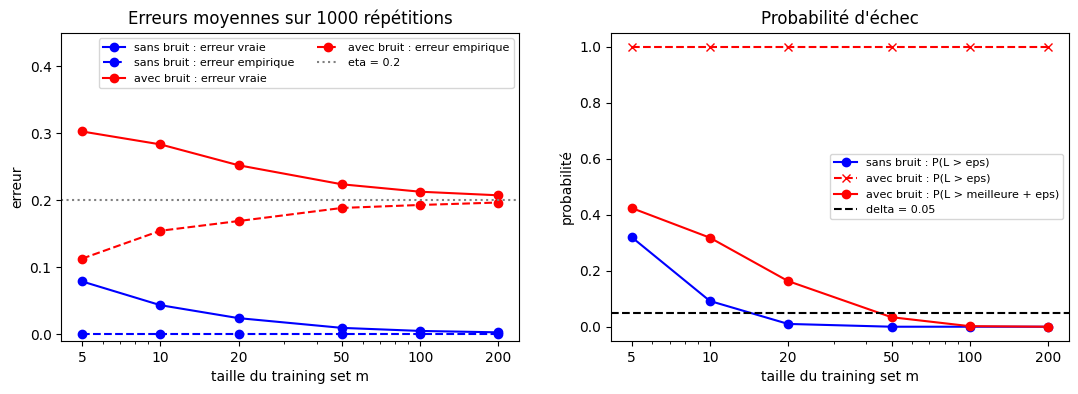

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# erreurs moyennes
ax = axes[0]
ax.plot(tailles, [res[m][1].mean() for m in tailles], "o-", color="blue", label="sans bruit : erreur vraie")
ax.plot(tailles, [res[m][0].mean() for m in tailles], "o--", color="blue", label="sans bruit : erreur empirique")
ax.plot(tailles, [res_b[m][1].mean() for m in tailles], "o-", color="red", label="avec bruit : erreur vraie")
ax.plot(tailles, [res_b[m][0].mean() for m in tailles], "o--", color="red", label="avec bruit : erreur empirique")
ax.axhline(eta, color="gray", linestyle=":", label="eta = 0.2")
ax.set_ylim(-0.01, 0.45)
ax.set_title("Erreurs moyennes sur 1000 répétitions")
ax.set_ylabel("erreur")
ax.legend(fontsize=8, ncol=2)

# probabilités d'échec
ax = axes[1]
ax.plot(tailles, proba, "o-", color="blue", label="sans bruit : P(L > eps)")
ax.plot(tailles, proba_pac, "x--", color="red", label="avec bruit : P(L > eps)")
ax.plot(tailles, proba_agn, "o-", color="red", label="avec bruit : P(L > meilleure + eps)")
ax.axhline(delta, color="black", linestyle="--", label="delta = 0.05")
ax.set_title("Probabilité d'échec")
ax.set_ylabel("probabilité")
ax.legend(fontsize=8)

for ax in axes:
    ax.set_xscale("log")
    ax.set_xticks(tailles)
    ax.set_xticklabels(tailles)
    ax.set_xlabel("taille du training set m")
plt.show()

**Commentaire.**

- **Erreurs moyennes (figure de gauche).** Avec le bruit, l'erreur vraie diminue quand $m$ augmente (de 0.30 à 0.21) mais elle se rapproche de 0.2, pas de 0. L'erreur empirique est plus petite que 0.2 pour les petits $m$ (0.11 pour $m = 5$) puis remonte vers 0.2. Avec peu de points, ERM s'adapte aussi au bruit, donc l'erreur empirique est trop optimiste.
- **Critère PAC.** La probabilité $\Pr(L_D(h_S) > \varepsilon)$ vaut 1 pour toutes les tailles. C'est logique : tous les seuils ont une erreur d'au moins 0.2, qui est plus grand que $\varepsilon = 0.1$. Avoir une erreur plus petite que $\varepsilon$ est impossible, même avec beaucoup de données.
- **Critère Agnostic PAC.** Si on compare à la meilleure erreur possible, la probabilité $\Pr(L_D(h_S) > \min_h L_D(h) + \varepsilon)$ diminue bien : 0.42, 0.32, 0.16, 0.03, 0.002, 0. Elle passe sous $\delta$ à partir de $m = 50$.
- Il faut donc plus d'exemples que sans bruit pour la même garantie : $m = 50$ au lieu de $m = 20$.

### Questions

**Can the empirical error still reach zero?**

En général non. Sans bruit, l'erreur empirique est toujours 0. Avec le bruit, elle vaut 0 seulement pour de très petits training sets, quand par chance les labels restent séparables : 51 % des cas pour $m = 5$, 17 % pour $m = 10$, 2 % pour $m = 20$, et jamais à partir de $m = 50$. Pour les grands $m$ elle se stabilise autour de 0.2. Et même quand elle vaut 0, l'erreur vraie reste d'au moins 0.2.

**Does increasing the number of training examples still improve the generalization performance?**

Oui. L'erreur vraie moyenne passe de 0.30 pour $m = 5$ à 0.21 pour $m = 200$, et l'écart entre l'erreur vraie et l'erreur empirique diminue (de 0.19 à 0.01). Mais la limite n'est plus la même : l'erreur vraie tend vers 0.2 et pas vers 0. Plus de données permet de se rapprocher du meilleur seuil, mais ne peut pas enlever l'erreur causée par le bruit.

**How do your observations relate to the PAC and Agnostic PAC learning frameworks?**

Le cadre PAC suppose qu'il existe une hypothèse parfaite dans $\mathcal{H}$ et demande une erreur vraie plus petite que $\varepsilon$. C'est ce qu'on observe dans la partie 4. Avec le bruit, cette hypothèse est fausse et l'objectif PAC ne peut plus être atteint (la probabilité d'échec reste à 1).

Le cadre Agnostic PAC ne fait plus cette hypothèse. Il demande seulement d'être proche de la meilleure hypothèse de la classe : $L_D(h_S) \le \min_{h \in \mathcal{H}} L_D(h) + \varepsilon$. C'est ce qu'on observe dans la partie 5 : ERM atteint cet objectif quand $m$ est assez grand.

Sans bruit, la meilleure erreur vaut 0 et les deux définitions donnent la même chose. Le cadre PAC est donc un cas particulier du cadre agnostique.

## Conclusion

| | PAC (sans bruit) | Agnostic PAC (bruit de 20 %) |
|---|---|---|
| Erreur empirique de ERM | toujours 0 | presque jamais 0, proche de 0.2 |
| Erreur vraie quand $m$ augmente | tend vers 0 | tend vers 0.2 |
| Objectif | erreur $\le \varepsilon$ | erreur $\le$ meilleure erreur $+ \varepsilon$ |
| Taille pour passer sous $\delta$ | $m = 20$ | $m = 50$ |

Le même algorithme ERM marche dans les deux cas, mais on ne peut pas lui demander la même chose.

Dans le cas réalisable, ERM ne fait aucune erreur sur le training set et son erreur vraie tend vers 0 : avec assez d'exemples, l'erreur est plus petite que $\varepsilon$ avec une grande probabilité. C'est le cadre PAC.

Avec du bruit, aucun seuil n'est parfait, donc demander une erreur proche de 0 n'a plus de sens. Le cadre Agnostic PAC demande à la place d'être presque aussi bon que le meilleur seuil de la classe. Les expériences montrent que ERM y arrive, mais qu'il faut plus d'exemples.

Enfin, l'erreur empirique seule peut tromper : elle vaut 0 dans le cas réalisable alors que l'erreur vraie ne l'est pas, et elle est plus petite que l'erreur vraie dans le cas bruité. Il faut un test set indépendant pour savoir si le modèle généralise.